# 06 — Tinggi bangunan dan geodatabase

1. Jumlah lantai total `levels` dari OSM `building:levels`; bila kosong, dari median tinggi Open Buildings 2.5D
   di footprint.
2. `Bld_Height = GFl + Fl × N + 1,0` (Pers. 1). Di sini `N` = jumlah lantai **di atas lantai dasar**
   (`levels − 1`), karena lantai dasar sudah dihitung lewat `GFl`. Dengan `N = levels` (PRD awal) satu lantai
   terhitung dua kali: gedung 1 lantai jadi 8,5 m padahal 2.5D ±5 m. Dari tinggi 2.5D:
   `N = max(0, round((h − GFl − 1,0) / Fl))`.
3. Elevasi dasar = persentil 10 DEM 8 m di footprint, agar gedung menempel ke terrain.
4. Atribut non-spasial: nama, kategori, sumber footprint.
5. Semua layer ke satu GeoPackage `output/ui3d.gpkg`.

**Output**: `ui3d.gpkg` (aoi, buildings, roads, water, vegetation, terrain_points, + gob/dl buildings bila ada).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ui3d_common import CFG, aoi, interim, out, raw, savefig, zonal

Bc = CFG["building"]
GFl, Fl, K = Bc["GFl"], Bc["Fl"], Bc["roof_const"]
b = gpd.read_file(out("ref_buildings.gpkg"))

## 1–2. Jumlah lantai dan tinggi

In [2]:
lv = pd.to_numeric(b.get("building:levels", pd.Series(np.nan, index=b.index)), errors="coerce")
h25 = zonal(b, raw("gob_25d"), np.median, band=2)  # band 2 = building_height (m)
N_25d = np.maximum(0, np.round((h25 - GFl - K) / Fl))

b["h_25d_m"] = np.round(h25, 2)
b["N"] = np.where(lv > 0, np.round(lv) - 1, np.where(np.isfinite(N_25d), N_25d, 0)).astype(int)
b["levels"] = b.N + 1
b["N_source"] = np.where(lv > 0, "OSM building:levels", np.where(np.isfinite(N_25d), "OpenBuildings2.5D", "default=0"))
b["Bld_Height"] = GFl + Fl * b.N + K
print(b.N_source.value_counts().to_string())
b[["levels", "N", "Bld_Height"]].describe().T

N_source
OpenBuildings2.5D      880
OSM building:levels    115


,count,mean,std,min,25%,50%,75%,max
levels,995.0,1.667337,1.943075,1.0,1.0,1.0,2.0,29.0
N,995.0,0.667337,1.943075,0.0,0.0,0.0,1.0,28.0
Bld_Height,995.0,7.335678,6.800764,5.0,5.0,5.0,8.5,103.0


## 3. Elevasi dasar dari DEM (persentil 10)

In [3]:
dem = out("dem_ui_8m.tif")
b["base_elev"] = np.round(zonal(b, dem, lambda v: np.percentile(v, Bc["base_elev_percentile"])), 2)
print("Gedung tanpa elevasi dasar:", int(b.base_elev.isna().sum()))

Gedung tanpa elevasi dasar: 0


## 4. Atribut non-spasial dan cek konsistensi

Bld_Height − tinggi 2.5D: median 0.52 m, MAE 1.87 m (n=995)


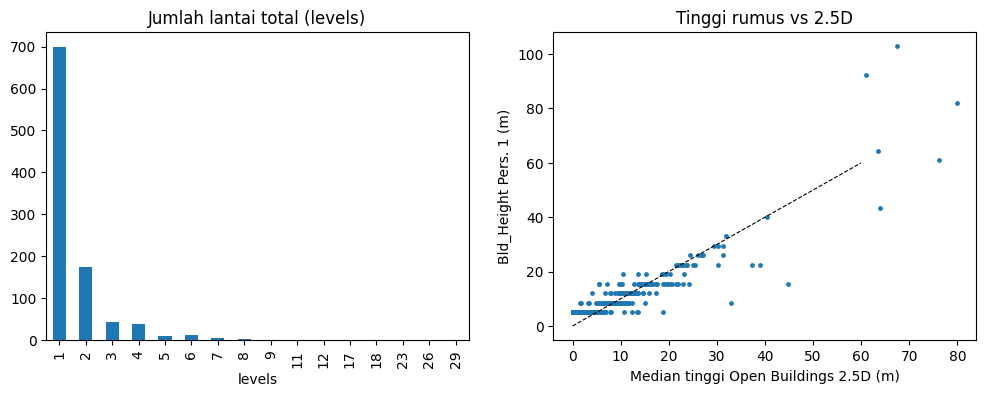

In [4]:
b["name"] = b["name"].fillna("")
cols = ["id", "name", "category", "building", "footprint_source", "area_m2", "levels", "N", "N_source", "h_25d_m",
        "Bld_Height", "base_elev", "geometry"]
buildings = b[[c for c in cols if c in b.columns]]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
buildings.levels.value_counts().sort_index().plot.bar(ax=ax[0], title="Jumlah lantai total (levels)")
ok = buildings.h_25d_m.notna()
ax[1].scatter(buildings.h_25d_m[ok], buildings.Bld_Height[ok], s=6)
ax[1].plot([0, 60], [0, 60], "k--", lw=0.8)
ax[1].set(xlabel="Median tinggi Open Buildings 2.5D (m)", ylabel="Bld_Height Pers. 1 (m)",
          title="Tinggi rumus vs 2.5D")
savefig(fig, "fig_tinggi_bangunan.png")
d = (buildings.Bld_Height - buildings.h_25d_m)[ok]
print(f"Bld_Height − tinggi 2.5D: median {d.median():.2f} m, MAE {d.abs().mean():.2f} m (n={ok.sum()})")
plt.show()

## 5. Tulis geodatabase `ui3d.gpkg`

In [5]:
gdb = out("ui3d.gpkg")
gdb.unlink(missing_ok=True)
lay = interim("osm_layers.gpkg")
layers = {"aoi": aoi("aoi"), "buildings": buildings,
          "roads": gpd.read_file(lay, layer="roads"), "water": gpd.read_file(lay, layer="water"),
          "vegetation": gpd.read_file(lay, layer="vegetation"),
          "terrain_points": gpd.read_file(interim("terrain_points.gpkg"))}
for name, path in (("gob_buildings", out("gob_buildings.gpkg")), ("dl_buildings", out("dl_buildings.gpkg"))):
    if path.exists():
        layers[name] = gpd.read_file(path)
for name, g in layers.items():
    g.to_file(gdb, layer=name)
    print(f"{name:15s} {len(g):6d} fitur")

aoi                  1 fitur


buildings          995 fitur
roads              863 fitur


water               19 fitur


vegetation         118 fitur
terrain_points    1249 fitur


gob_buildings     1254 fitur


dl_buildings      1803 fitur
